# F4.2 — Régimen dinámico

**Procedencia.**
- Reintentos de Gray-Scott: regeneración de las 908 imágenes de `train` por la ruta CPU en Kaggle, commit `c121ab6` (`results/f42_regimen/reintentos/`).
- Análisis: `python -m src.fase4.regimen --resoluciones results/f42_regimen/resoluciones.json`, una sola vez (`results/f42_regimen/resultados.json`, `regimen_run.log`).
- Este notebook **no reajusta modelos ni hace inferencia**. Recalcula los mapeos (f, k), ρ y octavas desde **u** (`umap_params.pkl`, verificado contra el manifiesto) solo para dibujar, y comprueba antes que los conteos coinciden con `resultados.json`. Las cifras salen de `resultados.json` y de `results/canonical_numbers.json` (`f42.*`).
- La adenda de la capa C de F0.3 (Lorenz) está pospuesta por decisión del equipo y no se usa aquí.

**Regla de lectura** (`docs/plan_fase4.md`, F4.2, «qué se afirma / qué no»).
- Diferencia significativa por clase (Holm) en Lorenz o Perlin: las clases ocupan regiones de parámetros distintas. **No** que el clasificador use el régimen, ni que el régimen tenga contenido emocional.
- Gray-Scott: solo dispersión de (f, k), **sin** fronteras de Pearson (no hay fuente versionada; resolución `pearson`). Ninguna afirmación de régimen.
- Tasa de reintentos distinta por clase (Holm): el *wrapper* introduce una diferencia por clase vía **u** que el modelo podría aprovechar. **No** es una fuga de etiqueta: el *wrapper* no recibe la etiqueta (F0.3).
- F1 por estrato de Lorenz: descriptivo; el estrato ρ < 24.74 de prueba es pequeño.

In [1]:
%matplotlib inline
import csv
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
for p in (REPO, REPO / 'src', REPO / 'src' / 'training', REPO / 'src' / 'generation'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from viz import style
from src.fase4 import regimen as rg

style.apply()
D = REPO / 'results' / 'f42_regimen'
FIG = D / 'figures'
DOC = json.loads((D / 'resultados.json').read_text(encoding='utf-8'))
R = DOC['resultados']
CANON_DOC = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))
CANON = CANON_DOC['numbers']
CLASES = ((1, 'Depresivo', style.TECH_COLOR['perlin'], 'o'), (0, 'No depresivo', style.TECH_COLOR['gray_scott'], 's'))
FIGS = []


def pie(fig, text, y=-0.02, x=0.01):
    fig.text(x, y, text, ha='left', va='top', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY, wrap=True)


def guardar(fig, nombre, descripcion):
    path = style.save(fig, FIG / nombre)
    FIGS.append({'archivo': path.relative_to(REPO).as_posix(), 'figura': descripcion})
    plt.show()
    return path


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def sha_lf(path):
    return hashlib.sha256(Path(path).read_bytes().replace(b'\r\n', b'\n')).hexdigest()

## 0. Procedencia y hashes

In [2]:
M = DOC['meta']
REINT = D / 'reintentos' / 'reintentos_gs_train.csv'
MAN = json.loads((D / 'reintentos' / 'reintentos_gs_manifest.json').read_text(encoding='utf-8'))
rows = [('HEAD de regimen.py (resultados.json:meta.git_commit)', M['git_commit']),
        ('Commit de Kaggle (reintentos_gs_manifest.json:git_commit)', MAN['git_commit']),
        ('smoke (manifiesto de Kaggle)', MAN['smoke']),
        ('Resoluciones (archivo, sha256)', f"{M['resoluciones']['archivo']} · {M['resoluciones']['sha256']}"),
        ('Resoluciones (valores)', json.dumps(R['resoluciones'], ensure_ascii=False))]
assert sha(REINT) == M['inputs']['results/f42_regimen/reintentos/reintentos_gs_train.csv'] == MAN['csv']['sha256']
rows.append(('reintentos_gs_train.csv — sha256 (= meta.inputs = manifiesto de Kaggle)', sha(REINT)))
for k, v in M['inputs'].items():
    if k.startswith('results/predictions/'):
        assert sha(REPO / k) == v, k
        rows.append((f'{k} — sha256 (= meta.inputs)', v))
assert CANON_DOC['inputs']['results/f42_regimen/resultados.json'] == sha_lf(D / 'resultados.json')
rows.append(('resultados.json — sha256 LF (= canonical_numbers.json:inputs)', sha_lf(D / 'resultados.json')))
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(rows, columns=['Campo', 'Valor'])

,Campo,Valor
0,HEAD de regimen.py (resultados.json:meta.git_commit),43ba00a9549c1ee9c972a544d3385871593854a6
1,Commit de Kaggle (reintentos_gs_manifest.json:git_commit),c121ab62f2718d7b9c299fbcde9f84bc26507a30
2,smoke (manifiesto de Kaggle),False
3,"Resoluciones (archivo, sha256)",results/f42_regimen/resoluciones.json · ee4fa94e91c514e0f0161dee060ac6c61cc3c76279bb4e6eae58344b6fddcbf4
4,Resoluciones (valores),"{""fisher_alternativa"": ""two-sided"", ""mw_continuidad"": true, ""reintento_evento"": ""reintentos_mayor_0"", ""f1_estrato_si..."
5,reintentos_gs_train.csv — sha256 (= meta.inputs = manifiesto de Kaggle),45a27867a7a0453a84c44794ff92bcfc7204be8c428d262951eb78d7cbf92a2c
6,results/predictions/final/lorenz__vit_b16__frozen__seed42.csv — sha256 (= meta.inputs),fcac7c6b35a380637b0462ee4d541ec69d911278eed02d5f634cd38b67f91b76
7,results/predictions/final/lorenz__vit_b16__frozen__seed7.csv — sha256 (= meta.inputs),67b61ae0124831f7f7011be3d30d68a01fd8d89079783f5a320614f8a6387e38
8,results/predictions/final/lorenz__vit_b16__frozen__seed123.csv — sha256 (= meta.inputs),0b66f60777549bcf2181f931bc10e85d2dd77ffc02d71d321c74359b9484b065
9,results/predictions/final/lorenz__vit_b16__frozen__seed2024.csv — sha256 (= meta.inputs),5e2e09af39e19ec568d24ab765ee340eb8d697314c4a72138f450e89a76c640e


## 1. Recalcular los mapeos desde u (solo para dibujar)

`u` de `train` con el dtype almacenado (`regimen.load_u`, que verifica `umap_params.pkl` contra el manifiesto y alinea por `idx`). Los mapeos son las funciones de `src/generation`. Se comprueba que los conteos coinciden con `resultados.json` antes de dibujar.

In [3]:
index = rg.load_index()
U = rg.load_u(index, ('train', 'test'))
U_tr, y = U['train']
mp = rg.mapear(U_tr)
%matplotlib inline
# (lorenz_lib fija el backend Agg al importarse; se restaura el backend inline del notebook)
dep, nodep = y == 1, y == 0
bajo = rg.estrato_lorenz(mp['rho'])
filas = rg.load_reintentos(REINT, index['train'])
reint = np.array([int(r['reintentos']) > 0 for r in filas])
assert [int(r['y_true']) for r in filas] == y.tolist()
L = R['lorenz']['proporcion_rho_menor']
assert (int(bajo[dep].sum()), int(bajo[nodep].sum())) == (L['n_dep'], L['n_nodep'])
assert {str(o): {'dep': int((mp['octavas'][dep] == o).sum()), 'nodep': int((mp['octavas'][nodep] == o).sum())}
        for o in sorted(set(mp['octavas'].tolist()))} == R['perlin']['octavas_por_clase']
G = R['gray_scott']['reintentos']
assert (int(reint[dep].sum()), int(reint[nodep].sum())) == (G['n_dep'], G['n_nodep'])
for c, m in (('dep', dep), ('nodep', nodep)):
    assert float(mp['f'][m].mean()) == R['gray_scott']['fk_por_clase'][c]['f_media']
    assert float(mp['k'][m].mean()) == R['gray_scott']['fk_por_clase'][c]['k_media']
print(f'train: n = {len(y)} ({int(dep.sum())} depresivas, {int(nodep.sum())} no depresivas); conteos = resultados.json')

train: n = 908 (353 depresivas, 555 no depresivas); conteos = resultados.json


## 2. Gray-Scott: dispersión de (f, k) por clase

Descriptivo, sin prueba. **Sin** superposición del diagrama de Pearson (1993): no hay en el repositorio una fuente versionada de sus fronteras (resolución `pearson` = `sin_superposicion_sin_fuente_versionada`). Fuente: `resultados.json:resultados.gray_scott.fk_por_clase`.

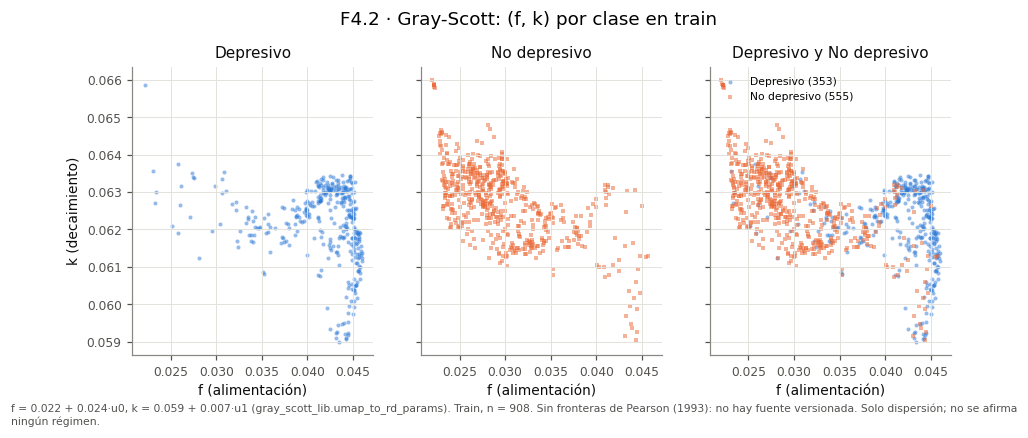

,f media,k media,f mín,f máx,k mín,k máx
dep,0.041313,0.062130,0.02216,0.046000,0.05900,0.06587
nodep,0.029878,0.062695,0.02200,0.045661,0.05905,0.06600


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.4), sharex=True, sharey=True)
for ax, sel in zip(axes, ((1,), (0,), (1, 0))):
    for c, lab, col, mk in CLASES:
        if c not in sel:
            continue
        m = y == c
        ax.scatter(mp['f'][m], mp['k'][m], s=7, alpha=0.5, color=col, marker=mk, linewidths=0, label=f'{lab} ({int(m.sum())})')
    ax.set_xlabel('f (alimentación)')
    ax.set_title(' y '.join(l for c, l, _, _ in CLASES if c in sel))
    ax.grid(True)
axes[0].set_ylabel('k (decaimiento)')
axes[2].legend(loc='upper left', fontsize=style.FONT_SIZES['annot'])
fig.suptitle('F4.2 · Gray-Scott: (f, k) por clase en train', y=1.03)
pie(fig, 'f = 0.022 + 0.024·u0, k = 0.059 + 0.007·u1 (gray_scott_lib.umap_to_rd_params). Train, n = 908. '
         'Sin fronteras de Pearson (1993): no hay fuente versionada. Solo dispersión; no se afirma ningún régimen.')
guardar(fig, 'f42_04_gray_scott_fk_por_clase', 'Dispersión de (f, k) por clase en train, sin fronteras de Pearson')
pd.DataFrame({c: {'f media': v['f_media'], 'k media': v['k_media'], 'f mín': v['f_rango'][0], 'f máx': v['f_rango'][1],
                  'k mín': v['k_rango'][0], 'k máx': v['k_rango'][1]} for c, v in R['gray_scott']['fk_por_clase'].items()}).T

## 3. Lorenz: ρ por clase con la línea 24.74

Fisher exacto bilateral sobre la proporción con ρ < 24.74 y Mann–Whitney bilateral (asintótico, con continuidad) de ρ; Holm con m = 4. Fuentes: `resultados.json:resultados.lorenz`, `…pruebas`, `…holm` (claves `f42.lorenz.*`).

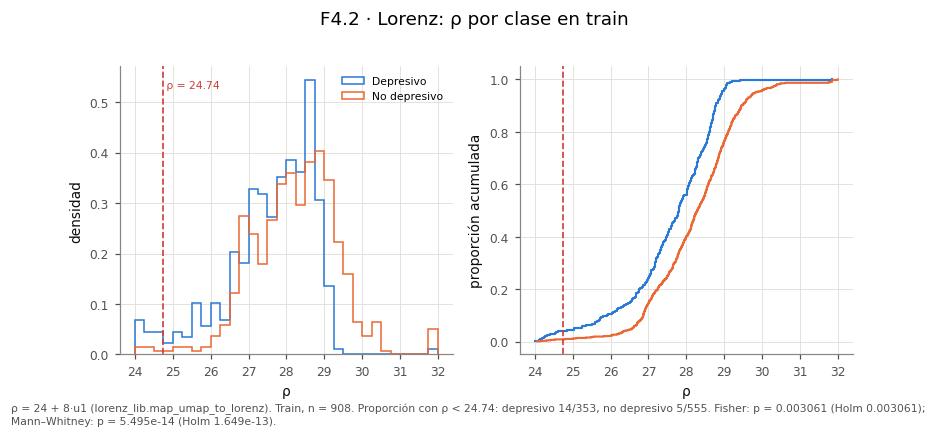

,n con ρ < 24.74,proporción,Q1 ρ,mediana ρ,Q3 ρ
dep,14.0,0.039660,27.037718,27.808583,28.505045
nodep,5.0,0.009009,27.504473,28.291022,28.969863


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
bins = np.linspace(24, 32, 33)
for c, lab, col, _ in CLASES:
    r = np.sort(mp['rho'][y == c])
    axes[0].hist(r, bins=bins, density=True, histtype='step', lw=1.5, color=col, label=lab)
    axes[1].step(r, np.arange(1, len(r) + 1) / len(r), where='post', color=col, lw=1.4, label=lab)
for ax in axes:
    ax.axvline(rg.LORENZ_RHO_UMBRAL, color=style.THRESHOLD_COLOR, ls='--', lw=1.1)
    ax.set_xlabel('ρ')
    ax.grid(True)
axes[0].text(rg.LORENZ_RHO_UMBRAL, axes[0].get_ylim()[1] * 0.95, ' ρ = 24.74', color=style.THRESHOLD_COLOR,
             fontsize=style.FONT_SIZES['annot'], va='top')
axes[0].set_ylabel('densidad')
axes[1].set_ylabel('proporción acumulada')
axes[0].legend(fontsize=style.FONT_SIZES['annot'])
fig.suptitle('F4.2 · Lorenz: ρ por clase en train', y=1.03)
P, H = R['pruebas'], R['holm']['familia']
pie(fig, f"ρ = 24 + 8·u1 (lorenz_lib.map_umap_to_lorenz). Train, n = 908. Proporción con ρ < 24.74: "
         f"depresivo {L['n_dep']}/{R['n_train']['dep']}, no depresivo {L['n_nodep']}/{R['n_train']['nodep']}. "
         f"Fisher: p = {P['lorenz_fisher_regimen']['p']:.4g} (Holm {H['lorenz_fisher_regimen']['p_holm']:.4g}); "
         f"Mann–Whitney: p = {P['lorenz_mw_rho']['p']:.4g} (Holm {H['lorenz_mw_rho']['p_holm']:.4g}).")
guardar(fig, 'f42_05_lorenz_rho_por_clase', 'Histograma y distribución acumulada de ρ por clase en train, con la línea 24.74')
pd.DataFrame({c: {'n con ρ < 24.74': L[f'n_{c}'], 'proporción': L[c], 'Q1 ρ': R['lorenz']['rho_cuartiles'][c][0],
                  'mediana ρ': R['lorenz']['rho_cuartiles'][c][1], 'Q3 ρ': R['lorenz']['rho_cuartiles'][c][2]}
              for c in ('dep', 'nodep')}).T

## 4. Perlin: octavas por clase

Mann–Whitney bilateral (asintótico, con continuidad). Fuente: `resultados.json:resultados.perlin.octavas_por_clase` y `…pruebas.perlin_mw_octavas`.

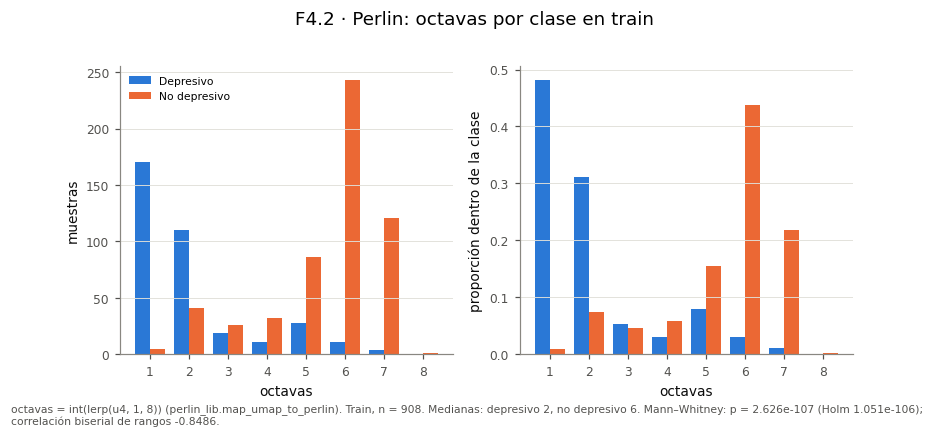

,dep,nodep
octavas,,
1,170,5
2,110,41
3,19,26
4,11,32
5,28,86
6,11,243
7,4,121
8,0,1


In [6]:
O = R['perlin']['octavas_por_clase']
octs = sorted(int(o) for o in O)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.4))
w = 0.38
for j, (c, lab, col, _) in enumerate(CLASES):
    k = 'dep' if c == 1 else 'nodep'
    n = np.array([O[str(o)][k] for o in octs])
    axes[0].bar(np.array(octs) + (j - 0.5) * w, n, width=w, color=col, label=lab)
    axes[1].bar(np.array(octs) + (j - 0.5) * w, n / n.sum(), width=w, color=col, label=lab)
for ax, yl in zip(axes, ('muestras', 'proporción dentro de la clase')):
    ax.set_xticks(octs)
    ax.set_xlabel('octavas')
    ax.set_ylabel(yl)
    ax.grid(axis='y')
axes[0].legend(fontsize=style.FONT_SIZES['annot'])
fig.suptitle('F4.2 · Perlin: octavas por clase en train', y=1.03)
pm = P['perlin_mw_octavas']
pie(fig, f"octavas = int(lerp(u4, 1, 8)) (perlin_lib.map_umap_to_perlin). Train, n = 908. Medianas: depresivo "
         f"{pm['mediana_dep']:g}, no depresivo {pm['mediana_nodep']:g}. Mann–Whitney: p = {pm['p']:.4g} "
         f"(Holm {H['perlin_mw_octavas']['p_holm']:.4g}); correlación biserial de rangos {pm['efecto_rbc']:.4f}.")
guardar(fig, 'f42_06_perlin_octavas_por_clase', 'Conteo y proporción de octavas por clase en train')
pd.DataFrame(O).T.rename_axis('octavas')

## 5. Gray-Scott: tasa de reintentos por clase

Evento = al menos un reintento del *wrapper* (`reintentos > 0`, resolución `reintento_evento`). Ninguna muestra usó el patrón de respaldo. Las 908 regeneradas son idénticas a las almacenadas por píxeles (criterio `bit_a_bit` = `pixeles`), así que no hay muestras en duda (`no_identicas` = 0 en ambas clases). Fuente: `resultados.json:resultados.gray_scott.reintentos`, `…bit_a_bit` y `…pruebas.gray_scott_fisher_reintentos`.

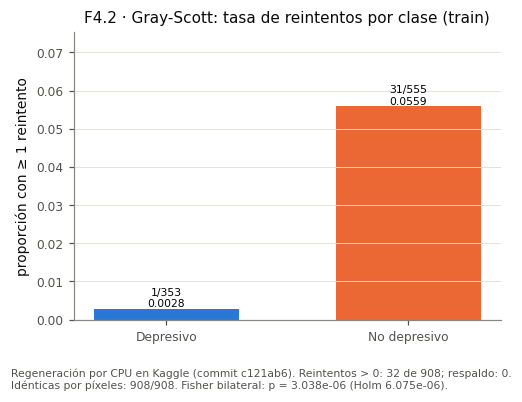

,muestras
reintentos,
0,876
1,32


In [7]:
fig, ax = plt.subplots(figsize=(5.0, 3.4))
for j, (c, lab, col, _) in enumerate(CLASES):
    k = 'dep' if c == 1 else 'nodep'
    tasa, n, N = G[f'tasa_{k}'], G[f'n_{k}'], R['n_train'][k]
    assert CANON[f'f42.gray_scott.reintentos.tasa.{k}']['value']['train'] == tasa
    ax.bar(j, tasa, color=col, width=0.6)
    ax.text(j, tasa, f'{n}/{N}\n{tasa:.4f}', ha='center', va='bottom', fontsize=style.FONT_SIZES['annot'])
ax.set_xticks([0, 1], [l for _, l, _, _ in CLASES])
ax.set_ylabel('proporción con ≥ 1 reintento')
ax.set_ylim(0, max(G['tasa_dep'], G['tasa_nodep']) * 1.35)
ax.grid(axis='y')
ax.set_title('F4.2 · Gray-Scott: tasa de reintentos por clase (train)')
pg = P['gray_scott_fisher_reintentos']
B = R['gray_scott']['bit_a_bit']
pie(fig, f"Regeneración por CPU en Kaggle (commit {MAN['git_commit'][:7]}). Reintentos > 0: {G['n_reintentos_mayor_0']} "
         f"de {R['n_train']['total']}; respaldo: {G['n_respaldo']}. Idénticas por píxeles: {B['n_identicas']}/{B['n_total']}. "
         f"Fisher bilateral: p = {pg['p']:.4g} (Holm {H['gray_scott_fisher_reintentos']['p_holm']:.4g}).")
guardar(fig, 'f42_07_gray_scott_reintentos_por_clase', 'Tasa de reintentos del wrapper de Gray-Scott por clase en train')
dist = pd.Series([int(r['reintentos']) for r in filas]).value_counts().sort_index()
pd.DataFrame({'muestras': dist}).rename_axis('reintentos')

## 6. Lorenz: F1 por estrato de ρ en prueba

Finalista de Lorenz (ViT-B/16 congelado), ŷ = 1[media de `p_dep` de las 5 semillas > 0.5], con las predicciones de prueba archivadas de F3.5; uso posterior al commit del veredicto de la Fase 5 (G1), sin inferencia nueva (G2). Descriptivo. Fuente: `resultados.json:resultados.lorenz_estratos_prueba` (claves `f42.lorenz.estrato_prueba.*`, verificadas desde las predicciones).

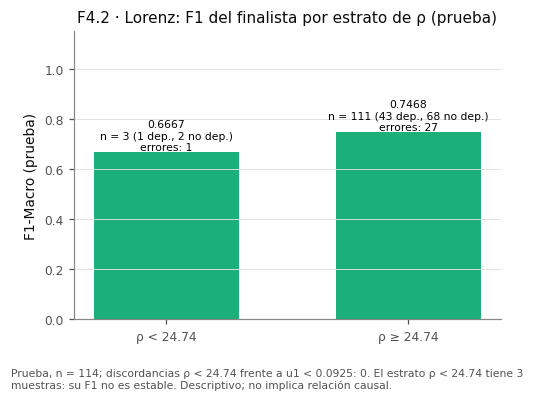

,n,n_dep,n_nodep,errores,f1_macro
ρ < 24.74,3.0,1.0,2.0,1.0,0.666667
ρ ≥ 24.74,111.0,43.0,68.0,27.0,0.746811


In [8]:
E = R['lorenz_estratos_prueba']
ests = [('rho_menor_24.74', 'ρ < 24.74', 'rho_menor_24_74'), ('rho_mayor_igual_24.74', 'ρ ≥ 24.74', 'rho_mayor_igual_24_74')]
fig, ax = plt.subplots(figsize=(5.0, 3.4))
for j, (k, lab, ck) in enumerate(ests):
    x = E[k]
    assert CANON[f'f42.lorenz.estrato_prueba.{ck}.f1_macro']['value']['test'] == x['f1_macro']
    ax.bar(j, x['f1_macro'], color=style.TECH_COLOR['lorenz'], width=0.6)
    ax.text(j, x['f1_macro'], f"{x['f1_macro']:.4f}\nn = {x['n']} ({x['n_dep']} dep., {x['n_nodep']} no dep.)\nerrores: {x['errores']}",
            ha='center', va='bottom', fontsize=style.FONT_SIZES['annot'])
ax.set_xticks([0, 1], [l for _, l, _ in ests])
ax.set_ylim(0, 1.15)
ax.set_ylabel('F1-Macro (prueba)')
ax.grid(axis='y')
ax.set_title('F4.2 · Lorenz: F1 del finalista por estrato de ρ (prueba)')
pie(fig, f"Prueba, n = 114; discordancias ρ < 24.74 frente a u1 < 0.0925: {E['discordancias_rho_vs_u1']}. "
         'El estrato ρ < 24.74 tiene 3 muestras: su F1 no es estable. Descriptivo; no implica relación causal.')
guardar(fig, 'f42_08_lorenz_f1_por_estrato', 'F1-Macro del finalista de Lorenz por estrato de ρ en prueba')
pd.DataFrame({lab: {q: E[k][q] for q in ('n', 'n_dep', 'n_nodep', 'errores', 'f1_macro')} for k, lab, _ in ests}).T

## 7. Familia de Holm (m = 4)

Fuente: `resultados.json:resultados.holm` (claves `f42.*.p`, `f42.*.p_holm`, `f42.*.holm.*`).

In [9]:
NOM = {'lorenz_fisher_regimen': 'Lorenz · Fisher ρ < 24.74', 'lorenz_mw_rho': 'Lorenz · Mann–Whitney ρ',
       'perlin_mw_octavas': 'Perlin · Mann–Whitney octavas', 'gray_scott_fisher_reintentos': 'Gray-Scott · Fisher reintentos'}
pd.DataFrame([{'prueba': NOM[k], 'p': h['p'], 'p ajustado (Holm)': h['p_holm'], 'rango': h['rank'], 'α_h': h['alpha_h'],
               'rechaza H0': h['reject']} for k, h in H.items()])

,prueba,p,p ajustado (Holm),rango,α_h,rechaza H0
0,Lorenz · Fisher ρ < 24.74,3.061481e-03,3.061481e-03,4,0.050000,True
1,Lorenz · Mann–Whitney ρ,5.495420e-14,1.648626e-13,2,0.016667,True
2,Perlin · Mann–Whitney octavas,2.626278e-107,1.050511e-106,1,0.012500,True
3,Gray-Scott · Fisher reintentos,3.037613e-06,6.075226e-06,3,0.025000,True


## 8. Figuras generadas

In [10]:
pd.DataFrame(FIGS)

,archivo,figura
0,results/f42_regimen/figures/f42_04_gray_scott_fk_por_clase.png,"Dispersión de (f, k) por clase en train, sin fronteras de Pearson"
1,results/f42_regimen/figures/f42_05_lorenz_rho_por_clase.png,"Histograma y distribución acumulada de ρ por clase en train, con la línea 24.74"
2,results/f42_regimen/figures/f42_06_perlin_octavas_por_clase.png,Conteo y proporción de octavas por clase en train
3,results/f42_regimen/figures/f42_07_gray_scott_reintentos_por_clase.png,Tasa de reintentos del wrapper de Gray-Scott por clase en train
4,results/f42_regimen/figures/f42_08_lorenz_f1_por_estrato.png,F1-Macro del finalista de Lorenz por estrato de ρ en prueba
